# 06 Forecasting and repeat purchase (BQ6): R version

**BQ6:** What will weekly revenue be over the next quarter, and which customers will buy again?

Same data, models and definitions as `06_forecast_repeat_py.ipynb` (see it for the full explanation).
The benchmarks, the Fourier regression and the logistic model must match exactly; the Fourier + AR(1) model
(`arima()` with regressors) should agree with Python's `SARIMAX` to about three decimals. Prophet (Stan) and
XGBoost use the same underlying libraries as Python and should agree closely, though not to the last decimal.

## Setup and data

In [ ]:
suppressPackageStartupMessages({
  library(arrow); library(dplyr); library(tidyr); library(ggplot2); library(scales)
  library(rpart); library(rpart.plot)
})
HAS_PROPHET <- requireNamespace("prophet", quietly = TRUE)
HAS_XGB     <- requireNamespace("xgboost", quietly = TRUE)
if (!HAS_PROPHET) cat("Package 'prophet' not installed: the Prophet model will be skipped.\n")
if (!HAS_XGB)     cat("Package 'xgboost' not installed: gradient boosting will be skipped.\n")
options(dplyr.summarise.inform = FALSE, scipen = 999, digits = 4, width = 160,
        repr.plot.width = 11, repr.plot.height = 4)
Sys.setenv(TZ = "UTC")

root <- if (dir.exists("data")) "." else ".."
proc <- file.path(root, "data", "processed")
fig  <- file.path(root, "reports", "figures")
dir.create(fig, showWarnings = FALSE, recursive = TRUE)

H      <- 13
PERIOD <- 365.25 / 7
K_MAX  <- 10

read_tbl <- function(name) {
  read_parquet(file.path(proc, paste0(name, ".parquet"))) |>
    mutate(across(c(date, week_start), as.Date)) |>
    filter(line_type == "product")                                  # T5, T6
}
prod <- read_tbl("sales_clean")
canc <- read_tbl("cancellations")
invisible(gc())
cat(sprintf("Product sales lines: %s   product cancellation lines: %s\n", comma(nrow(prod)), comma(nrow(canc))))

Product sales lines: 1,003,357   product cancellation lines: 17,915


# Part A: Weekly revenue forecast

In [ ]:
net_w <- bind_rows(prod |> select(week_start, revenue), canc |> select(week_start, revenue)) |>
  group_by(week_start) |> summarise(net = sum(revenue))
all_weeks <- seq(min(net_w$week_start), max(net_w$week_start), by = "week")
weekly <- tibble(week = all_weeks) |>
  left_join(net_w, by = c("week" = "week_start")) |>
  mutate(net = coalesce(net, 0) / 1000) |>
  slice(2:(n() - 1))                                                # drop partial weeks
y_all <- weekly$net
weeks_all <- weekly$week

design <- function(weeks, t, K) {
  m <- as.integer(format(weeks, "%m")); d <- as.integer(format(weeks, "%d"))
  X <- cbind(const = 1, t = as.numeric(t),
             xmas_partial = as.numeric(m == 12 & d >= 18 & d <= 24),
             xmas_closed  = as.numeric(m == 12 & d >= 25))
  for (k in seq_len(K)) {
    X <- cbind(X, sin(2 * pi * k * t / PERIOD), cos(2 * pi * k * t / PERIOD))
    colnames(X)[ncol(X) - 1:0] <- c(paste0("sin", k), paste0("cos", k))
  }
  X
}

n <- length(y_all)
t_all <- seq_len(n)
tr <- 1:(n - H); te <- (n - H + 1):n
y_train <- y_all[tr]; y_test <- y_all[te]
cat(sprintf("Weeks: %d (%s to %s)\n", n, weeks_all[1], weeks_all[n]))
cat(sprintf("Train: %d weeks to %s   Test: %d weeks from %s\n", length(tr), weeks_all[max(tr)], H, weeks_all[min(te)]))

Weeks: 104 (2009-12-07 to 2011-11-28)
Train: 91 weeks to 2011-08-29   Test: 13 weeks from 2011-09-05


## A1. Number of Fourier terms (AIC = n·log(RSS/n) + 2p, as in Python)

In [ ]:
aic_ols <- function(y, X) {
  fit <- lm.fit(X, y)
  length(y) * log(sum(fit$residuals^2) / length(y)) + 2 * ncol(X)
}
aic <- sapply(1:K_MAX, function(K) aic_ols(y_train, design(weeks_all[tr], t_all[tr], K)))
K_BEST <- which.min(aic)
print(data.frame(K = 1:K_MAX, AIC = round(aic, 2)), row.names = FALSE)
cat(sprintf("\nChosen K = %d\n", K_BEST))

  K   AIC
  1 700.1
  2 649.4
  3 633.6
  4 635.3
  5 636.4
  6 633.7
  7 627.5
  8 623.1
  9 625.5
 10 615.6

Chosen K = 10


## A2. Models and test-set accuracy

In [ ]:
X_train <- design(weeks_all[tr], t_all[tr], K_BEST)
X_test  <- design(weeks_all[te], t_all[te], K_BEST)

fc <- tibble(week = weeks_all[te], actual = y_test,
             naive = y_train[length(y_train)],
             seasonal_naive = y_all[te - 52])

ols <- lm.fit(X_train, y_train)
fc$fourier_ols <- drop(X_test %*% ols$coefficients)

arx <- arima(y_train, order = c(1, 0, 0), xreg = X_train[, -1], include.mean = TRUE, method = "ML")
pr  <- predict(arx, n.ahead = H, newxreg = X_test[, -1])
fc <- fc |> mutate(fourier_ar1 = as.numeric(pr$pred),
                   ar1_lo95 = fourier_ar1 - qnorm(0.975) * as.numeric(pr$se),
                   ar1_hi95 = fourier_ar1 + qnorm(0.975) * as.numeric(pr$se))

prophet_forecast <- function(weeks_fit, y_fit, weeks_new) {
  if (!HAS_PROPHET) return(rep(NA_real_, length(weeks_new)))
  frame <- function(w) {
    d <- design(w, rep(0, length(w)), 0)
    data.frame(ds = w, xmas_partial = d[, "xmas_partial"], xmas_closed = d[, "xmas_closed"])
  }
  m <- prophet::prophet(yearly.seasonality = 10, weekly.seasonality = FALSE, daily.seasonality = FALSE,
                        interval.width = 0.95, fit = FALSE)
  m <- prophet::add_regressor(m, "xmas_partial", standardize = FALSE)
  m <- prophet::add_regressor(m, "xmas_closed", standardize = FALSE)
  df <- frame(weeks_fit); df$y <- y_fit
  m <- suppressMessages(prophet::fit.prophet(m, df))
  predict(m, frame(weeks_new))$yhat
}
fc$prophet <- prophet_forecast(weeks_all[tr], y_train, weeks_all[te])

accuracy <- function(a, f) {
  e <- a - f
  c(MAE = mean(abs(e)), RMSE = sqrt(mean(e^2)), MAPE = mean(abs(e) / a) * 100,
    WAPE = sum(abs(e)) / sum(a) * 100, bias_pct = (sum(f) / sum(a) - 1) * 100)
}
MODELS <- c("naive", "seasonal_naive", "fourier_ols", "fourier_ar1", "prophet")
acc <- t(sapply(MODELS, function(m) accuracy(fc$actual, fc[[m]])))
r2 <- 1 - sum(ols$residuals^2) / sum((y_train - mean(y_train))^2)
cat(sprintf("AR(1) coefficient: %.4f   Fourier regression R² (train): %.3f\n\n", coef(arx)[["ar1"]], r2))
print(round(acc, 3))

AR(1) coefficient: -0.1657   Fourier regression R² (train): 0.865

                  MAE   RMSE  MAPE  WAPE bias_pct
naive          134.81 146.20 47.21 49.56  -49.557
seasonal_naive  42.66  52.91 18.00 15.68   -4.488
fourier_ols     40.27  50.41 16.47 14.80   -5.145
fourier_ar1     40.36  50.48 16.50 14.84   -5.152
prophet         40.27  50.40 16.46 14.80   -5.141


Test weeks, £k:
         week actual naive seasonal_naive fourier_ols fourier_ar1 prophet
1  2011-09-05  185.3 137.2          127.8       123.6       123.5   123.6
2  2011-09-12  222.3 137.2          160.9       151.6       151.5   151.6
3  2011-09-19  319.7 137.2          235.9       217.5       217.3   217.5
4  2011-09-26  202.4 137.2          287.1       279.7       279.3   279.7
5  2011-10-03  300.3 137.2          254.4       295.9       295.7   295.9
6  2011-10-10  204.3 137.2          305.2       265.7       265.7   265.7
7  2011-10-17  259.1 137.2          232.4       230.7       230.8   230.7
8  2011-10-24  234.2 137.2          202.2       232.2       232.0   232.3
9  2011-10-31  288.3 137.2          274.4       272.8       272.2   272.8
10 2011-11-07  350.1 137.2          359.4       319.1       318.6   319.1
11 2011-11-14  369.1 137.2          342.7       338.9       339.0   338.9
12 2011-11-21  295.2 137.2          286.3       327.2       328.0   327.2
13 2011-11-28  306.1 1

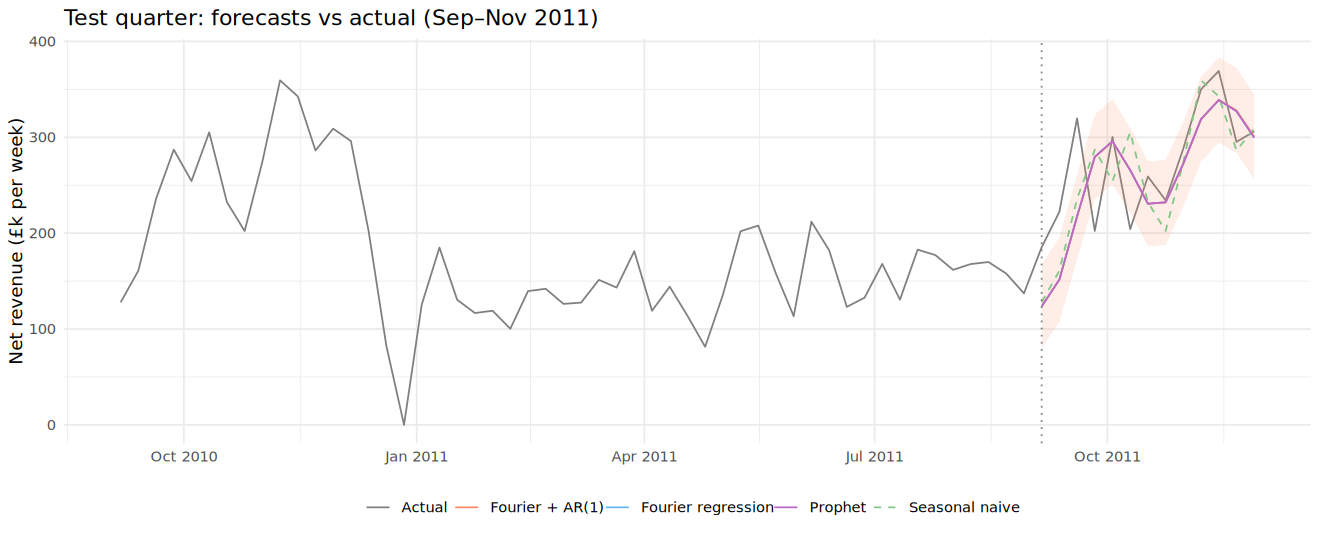

In [ ]:
cat("Test weeks, £k:\n")
print(as.data.frame(fc |> select(week, actual, all_of(MODELS)) |> mutate(across(-week, \(x) round(x, 1)))))

hist <- tibble(week = weeks_all, actual = y_all) |> filter(week >= weeks_all[min(te)] - 52 * 7)
p_test <- ggplot() +
  geom_line(data = hist, aes(week, actual, colour = "Actual")) +
  geom_ribbon(data = fc, aes(week, ymin = ar1_lo95, ymax = ar1_hi95), fill = "#FF8A65", alpha = 0.15) +
  geom_line(data = fc, aes(week, seasonal_naive, colour = "Seasonal naive"), linetype = "dashed") +
  geom_line(data = fc, aes(week, fourier_ols, colour = "Fourier regression")) +
  geom_line(data = fc, aes(week, fourier_ar1, colour = "Fourier + AR(1)")) +
  geom_line(data = fc, aes(week, prophet, colour = "Prophet")) +
  geom_vline(xintercept = weeks_all[min(te)], linetype = "dotted", colour = "grey50") +
  scale_colour_manual(values = c("Actual" = "grey50", "Seasonal naive" = "#81C784",
                                 "Fourier regression" = "#64B5F6", "Fourier + AR(1)" = "#FF8A65",
                                 "Prophet" = "#BA68C8")) +
  labs(x = NULL, y = "Net revenue (£k per week)", colour = NULL,
       title = "Test quarter: forecasts vs actual (Sep–Nov 2011)") +
  theme_minimal(base_size = 11) + theme(legend.position = "bottom")
ggsave(file.path(fig, "bq6_forecast_test_r.png"), p_test, width = 11, height = 4.5, dpi = 150)
options(repr.plot.width = 11, repr.plot.height = 4.5); p_test

## A3. Forecast for the next quarter

In [ ]:
aic_full <- sapply(1:K_MAX, function(K) aic_ols(y_all, design(weeks_all, t_all, K)))
K_FULL <- which.min(aic_full)
X_all <- design(weeks_all, t_all, K_FULL)
fut_weeks <- seq(weeks_all[n] + 7, by = "week", length.out = H)
X_fut <- design(fut_weeks, (n + 1):(n + H), K_FULL)

arx_full <- arima(y_all, order = c(1, 0, 0), xreg = X_all[, -1], include.mean = TRUE, method = "ML")
pf <- predict(arx_full, n.ahead = H, newxreg = X_fut[, -1])
future <- tibble(week = fut_weeks, forecast = as.numeric(pf$pred),
                 lo95 = forecast - qnorm(0.975) * as.numeric(pf$se),
                 hi95 = forecast + qnorm(0.975) * as.numeric(pf$se),
                 seasonal_naive = y_all[(n - 51):(n - 52 + H)],
                 prophet = prophet_forecast(weeks_all, y_all, fut_weeks))
cat(sprintf("K = %d   AR(1) coefficient: %.4f\n", K_FULL, coef(arx_full)[["ar1"]]))
cat(sprintf("Next-quarter total: £%sk (seasonal naive £%sk, Prophet £%sk)\n\n",
            comma(sum(future$forecast), accuracy = 1), comma(sum(future$seasonal_naive), accuracy = 1),
            comma(sum(future$prophet), accuracy = 1)))
print(as.data.frame(future |> mutate(across(-week, \(x) round(x, 1)))))

K = 10   AR(1) coefficient: -0.1749
Next-quarter total: £1,890k (seasonal naive £1,766k, Prophet £1,880k)

         week forecast  lo95  hi95 seasonal_naive prophet
1  2011-12-05    271.6 221.3 321.9          296.1   272.5
2  2011-12-12    239.4 188.3 290.4          202.2   235.7
3  2011-12-19     80.9  29.9 132.0           82.6    80.1
4  2011-12-26      8.2 -42.9  59.3            0.0    15.8
5  2012-01-02    162.8 111.8 213.9          125.5   154.8
6  2012-01-09    161.0 110.0 212.1          184.9   157.8
7  2012-01-16    154.6 103.5 205.6          130.5   155.0
8  2012-01-23    137.0  86.0 188.1          116.7   138.0
9  2012-01-30    119.6  68.5 170.6          119.0   118.9
10 2012-02-06    118.0  67.0 169.1          100.3   116.2
11 2012-02-13    133.3  82.2 184.4          139.6   132.0
12 2012-02-20    149.8  98.7 200.8          142.0   149.6
13 2012-02-27    153.8 102.7 204.9          126.2   153.8


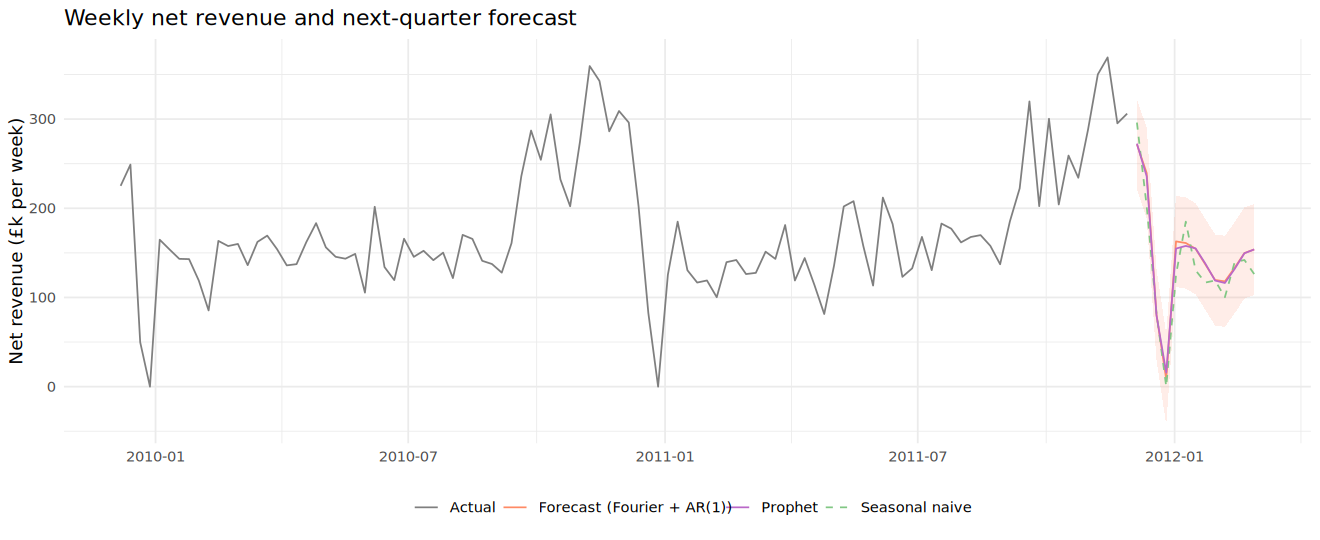

In [ ]:
p_fut <- ggplot() +
  geom_line(data = tibble(week = weeks_all, actual = y_all), aes(week, actual, colour = "Actual")) +
  geom_ribbon(data = future, aes(week, ymin = lo95, ymax = hi95), fill = "#FF8A65", alpha = 0.15) +
  geom_line(data = future, aes(week, forecast, colour = "Forecast (Fourier + AR(1))")) +
  geom_line(data = future, aes(week, seasonal_naive, colour = "Seasonal naive"), linetype = "dashed") +
  geom_line(data = future, aes(week, prophet, colour = "Prophet")) +
  scale_colour_manual(values = c("Actual" = "grey50", "Forecast (Fourier + AR(1))" = "#FF8A65",
                                 "Seasonal naive" = "#81C784", "Prophet" = "#BA68C8")) +
  labs(x = NULL, y = "Net revenue (£k per week)", colour = NULL,
       title = "Weekly net revenue and next-quarter forecast") +
  theme_minimal(base_size = 11) + theme(legend.position = "bottom")
ggsave(file.path(fig, "bq6_forecast_future_r.png"), p_fut, width = 11, height = 4.5, dpi = 150)
p_fut

# Part B: Repeat purchase (bought again within 90 days of the cut-off)

In [ ]:
customer_set <- function(start, cutoff) {
  start <- as.POSIXct(start, tz = "UTC"); cutoff <- as.POSIXct(cutoff, tz = "UTC")
  w <- prod |> filter(has_customer, invoice_date >= start, invoice_date < cutoff)
  c_cust <- canc |> filter(!is.na(customer_id), invoice_date >= start, invoice_date < cutoff) |>
    group_by(customer_id) |> summarise(cancelled = -sum(revenue))
  kept <- w |> filter(!cancelled_exact) |> group_by(customer_id) |>
    summarise(kept_sales = sum(revenue), orders = n_distinct(invoice))
  cut_d <- as.Date(cutoff)
  out_end <- cutoff + 90 * 86400
  nxt <- prod |> filter(has_customer, !cancelled_exact, invoice_date >= cutoff, invoice_date < out_end) |>
    distinct(customer_id) |> pull(customer_id)

  w |> group_by(customer_id) |>
    summarise(first_buy = min(date), last_buy = max(date), frequency = n_distinct(date),
              variety = n_distinct(stock_code), gross = sum(revenue), uk_share = mean(is_uk)) |>
    left_join(kept, by = "customer_id") |>
    left_join(c_cust, by = "customer_id") |>
    mutate(cancelled = coalesce(cancelled, 0),
           monetary = round(gross - cancelled, 2),
           avg_order_value = kept_sales / orders,
           recency_days = as.numeric(cut_d - last_buy),
           tenure_days = as.numeric(cut_d - first_buy),
           cancel_share = pmin(cancelled / gross, 1),
           is_uk = as.integer(uk_share >= 0.5)) |>
    filter(monetary > 0, !is.na(avg_order_value)) |>
    arrange(customer_id) |>
    mutate(bought_again = as.integer(customer_id %in% nxt))
}
train_c <- customer_set("2009-12-01", "2010-09-01")
test_c  <- customer_set("2010-12-01", "2011-09-01")
cat(sprintf("Train: %s customers, bought again within 90 days: %.1f%%\n", comma(nrow(train_c)), 100 * mean(train_c$bought_again)))
cat(sprintf("Test : %s customers, bought again within 90 days: %.1f%%\n", comma(nrow(test_c)), 100 * mean(test_c$bought_again)))

Train: 3,287 customers, bought again within 90 days: 58.4%
Test : 3,305 customers, bought again within 90 days: 56.1%


In [ ]:
CONT <- c("recency", "frequency", "order_value", "variety", "tenure", "cancel_share")
FEATURES <- c(CONT, "is_uk")
raw_features <- function(f) data.frame(
  recency = log1p(f$recency_days), frequency = log(f$frequency), order_value = log(f$avg_order_value),
  variety = log(f$variety), tenure = f$tenure_days, cancel_share = f$cancel_share, is_uk = f$is_uk)

raw_tr <- raw_features(train_c); raw_te <- raw_features(test_c)
mu <- sapply(raw_tr[CONT], mean); sdv <- sapply(raw_tr[CONT], sd)     # training statistics (sample SD)
std_tr <- raw_tr; std_te <- raw_te
std_tr[CONT] <- sweep(sweep(raw_tr[CONT], 2, mu), 2, sdv, "/")
std_te[CONT] <- sweep(sweep(raw_te[CONT], 2, mu), 2, sdv, "/")
std_tr$bought_again <- train_c$bought_again

logit <- glm(reformulate(FEATURES, "bought_again"), data = std_tr, family = binomial)
ci <- exp(confint.default(logit))
odds <- data.frame(odds_ratio = exp(coef(logit)), ci_low = ci[, 1], ci_high = ci[, 2],
                   p_value = summary(logit)$coefficients[, 4])[-1, ]
pseudo_r2 <- 1 - logLik(logit)[1] / logLik(update(logit, . ~ 1))[1]
cat(sprintf("Logistic regression (train): pseudo R² %.3f   log-likelihood %s\n\n",
            pseudo_r2, format(round(logLik(logit)[1], 2), big.mark = ",", nsmall = 2)))
print(round(odds, 3))

Logistic regression (train): pseudo R² 0.126   log-likelihood -1,950.56

             odds_ratio ci_low ci_high p_value
recency           0.936  0.828   1.058   0.289
frequency         2.311  1.967   2.715   0.000
order_value       1.126  1.030   1.231   0.009
variety           1.217  1.094   1.352   0.000
tenure            0.877  0.780   0.986   0.028
cancel_share      0.936  0.866   1.011   0.091
is_uk             0.956  0.713   1.281   0.762


## B2. Test performance and decision tree

In [ ]:
roc_points <- function(y, score) {
  o <- order(score, decreasing = TRUE); s <- score[o]; yy <- y[o]
  tp <- cumsum(yy); fp <- cumsum(1 - yy)
  last <- c(which(diff(s) != 0), length(s))
  data.frame(fpr = c(0, fp[last] / sum(1 - y)), tpr = c(0, tp[last] / sum(y)))
}
performance <- function(y, score) {
  n1 <- sum(y); n0 <- length(y) - n1
  auc_v <- (sum(rank(score)[y == 1]) - n1 * (n1 + 1) / 2) / (n1 * n0)
  r <- roc_points(y, score)
  c(auc = auc_v, gini = 2 * auc_v - 1, ks = max(r$tpr - r$fpr), brier = mean((score - y)^2))
}

y_te <- test_c$bought_again
p_logit <- as.numeric(predict(logit, newdata = std_te, type = "response"))

tree_df <- cbind(raw_tr, bought_again = factor(train_c$bought_again, levels = c(0, 1)))
tree <- rpart(reformulate(FEATURES, "bought_again"), data = tree_df, method = "class",
              parms = list(prior = c(0.5, 0.5)),
              control = rpart.control(maxdepth = 3, minbucket = 100, minsplit = 200, cp = -1, xval = 0))
p_tree <- predict(tree, newdata = raw_te, type = "prob")[, 2]

if (HAS_XGB) {
  XGB_PARAMS <- list(objective = "binary:logistic", max_depth = 3, eta = 0.05, min_child_weight = 1,
                     subsample = 1, colsample_bytree = 1, tree_method = "exact", nthread = 1)
  dtrain <- xgboost::xgb.DMatrix(as.matrix(raw_tr[FEATURES]), label = train_c$bought_again)
  gbm <- xgboost::xgb.train(params = XGB_PARAMS, data = dtrain, nrounds = 300, verbose = 0)
  p_gbm <- predict(gbm, xgboost::xgb.DMatrix(as.matrix(raw_te[FEATURES])))
} else p_gbm <- rep(NA_real_, length(y_te))

perf <- rbind(`Logistic regression` = performance(y_te, p_logit), `Decision tree` = performance(y_te, p_tree),
              `Gradient boosting` = if (HAS_XGB) performance(y_te, p_gbm) else rep(NA_real_, 4))
cat(sprintf("Test base rate: %.1f%%   (Brier score of always predicting it: %.3f)\n\n",
            100 * mean(y_te), mean((mean(y_te) - y_te)^2)))
print(round(perf, 3))
cat("\n"); print(tree)
if (HAS_XGB) {
  imp <- xgboost::xgb.importance(model = gbm)
  cat("\nGradient boosting, share of total gain by feature:\n")
  print(setNames(round(imp$Gain, 3), imp$Feature))
}

Test base rate: 56.1%   (Brier score of always predicting it: 0.246)

                      auc  gini    ks brier
Logistic regression 0.748 0.495 0.384 0.201
Decision tree       0.724 0.448 0.358 0.208
Gradient boosting   0.740 0.479 0.372 0.204

n= 3287 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

 1) root 3287 1643.00 0 (0.5000 0.5000)  
   2) frequency< 0.8959 2012  777.20 0 (0.6306 0.3694)  
     4) variety< 3.157 1116  367.60 0 (0.6917 0.3083)  
       8) frequency< 0.3466 892  274.20 0 (0.7146 0.2854) *
       9) frequency>=0.3466 224   93.40 0 (0.5965 0.4035) *
     5) variety>=3.157 896  409.60 0 (0.5506 0.4494)  
      10) variety< 3.818 552  229.60 0 (0.5975 0.4025) *
      11) variety>=3.818 344  160.90 1 (0.4720 0.5280) *
   3) frequency>=0.8959 1275  316.90 1 (0.2679 0.7321)  
     6) recency>=4.7 123   50.56 0 (0.6031 0.3969) *
     7) recency< 4.7 1152  240.10 1 (0.2274 0.7726)  
      14) frequency< 1.498 561  165.70 1 (0.3137 0.6863) *
      15

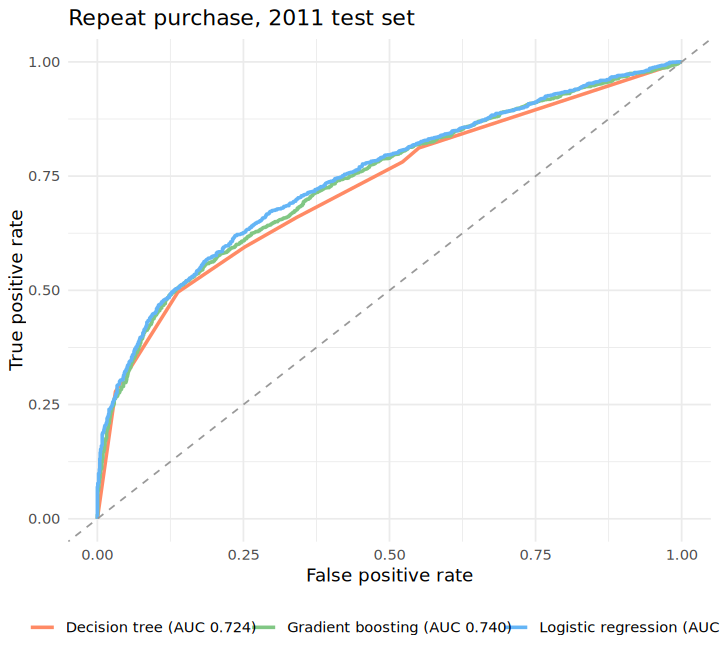

In [ ]:
roc_df <- bind_rows(
  roc_points(y_te, p_logit) |> mutate(model = sprintf("Logistic regression (AUC %.3f)", perf[1, "auc"])),
  roc_points(y_te, p_tree)  |> mutate(model = sprintf("Decision tree (AUC %.3f)", perf[2, "auc"])),
  if (HAS_XGB) roc_points(y_te, p_gbm) |> mutate(model = sprintf("Gradient boosting (AUC %.3f)", perf[3, "auc"])))
p_roc <- ggplot(roc_df, aes(fpr, tpr, colour = model)) + geom_line(linewidth = 1) +
  geom_abline(linetype = "dashed", colour = "grey60") +
  scale_colour_manual(values = c("#FF8A65", "#81C784", "#64B5F6")) +
  labs(x = "False positive rate", y = "True positive rate", colour = NULL,
       title = "Repeat purchase, 2011 test set") +
  theme_minimal(base_size = 11) + theme(legend.position = "bottom")
ggsave(file.path(fig, "bq6_repeat_roc_r.png"), p_roc, width = 6, height = 5.5, dpi = 150)
options(repr.plot.width = 6, repr.plot.height = 5.5); p_roc

## B3. Gains table (decile 1 = highest logistic score; ties broken by customer ID)

In [ ]:
g <- tibble(customer_id = test_c$customer_id, score = p_logit, y = y_te) |>
  mutate(decile = as.integer(ceiling(10 * rank(-score, ties.method = "first") / n())))
gains <- g |> group_by(decile) |>
  summarise(customers = n(), buyers = sum(y), mean_score = mean(score)) |>
  mutate(buy_rate = buyers / customers, cum_share_of_buyers = cumsum(buyers) / sum(buyers),
         lift = buy_rate / mean(y_te))
print(as.data.frame(gains), digits = 3)

   decile customers buyers mean_score buy_rate cum_share_of_buyers  lift
1       1       330    318      0.905    0.964               0.172 1.719
2       2       331    275      0.813    0.831               0.320 1.482
3       3       330    251      0.738    0.761               0.455 1.357
4       4       331    207      0.670    0.625               0.567 1.115
5       5       330    181      0.600    0.548               0.665 0.978
6       6       331    151      0.523    0.456               0.746 0.814
7       7       330    137      0.450    0.415               0.820 0.740
8       8       331    124      0.398    0.375               0.887 0.668
9       9       330    114      0.354    0.345               0.949 0.616
10     10       331     95      0.285    0.287               1.000 0.512


## Checks against Python

In [ ]:
dash <- file.path(root, "reports", "dashboard_data")
if (file.exists(file.path(dash, "forecast_accuracy.csv"))) {
  py_acc  <- read.csv(file.path(dash, "forecast_accuracy.csv"), row.names = 1)
  py_odds <- read.csv(file.path(dash, "repeat_odds.csv"), row.names = 1)
  py_perf <- read.csv(file.path(dash, "repeat_performance.csv"), row.names = 1)
  py_gain <- read.csv(file.path(dash, "repeat_gains.csv"))
  cat("Forecast accuracy, max |R - Python| per model (MAE, RMSE, MAPE, WAPE, bias):\n")
  print(signif(apply(abs(acc[rownames(py_acc), ] - as.matrix(py_acc)), 1, max), 3))
  cat(sprintf("\nOdds ratios, max |R - Python|: %.1e\n", max(abs(odds$odds_ratio - py_odds[rownames(odds), "odds_ratio"]))))
  cat(sprintf("Logistic AUC: R %.4f  Python %.4f   Tree AUC: R %.4f  Python %.4f\n",
              perf[1, "auc"], py_perf["Logistic regression", "auc"], perf[2, "auc"], py_perf["Decision tree", "auc"]))
  cat(sprintf("Gradient boosting AUC: R %.4f  Python %.4f\n", perf[3, "auc"], py_perf["Gradient boosting", "auc"]))
  cat(sprintf("Gains table buyers per decile identical: %s\n", identical(as.integer(gains$buyers), as.integer(py_gain$buyers))))
} else {
  cat("Run 06_forecast_repeat_py.ipynb first to create the dashboard CSVs.\n")
}

Forecast accuracy, max |R - Python| per model (MAE, RMSE, MAPE, WAPE, bias):
         naive seasonal_naive    fourier_ols    fourier_ar1        prophet 
     0.0000147      0.0000485      0.0000323      0.0466000      0.0000478 

Odds ratios, max |R - Python|: 3.5e-05
Logistic AUC: R 0.7476  Python 0.7476   Tree AUC: R 0.7240  Python 0.7240
Gradient boosting AUC: R 0.7396  Python 0.7396
Gains table buyers per decile identical: TRUE
